In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt


Data Augmentation function


In [4]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2), # Rotates randomly up to 20% of 360 degrees
    layers.RandomZoom(0.1),     # zoom 10%
    layers.RandomContrast(0.1),  # contrast 10%
    layers.RandomBrightness(0.2) #
], name="data_augmentation_pipeline")

Visual Test of Data Augmentation

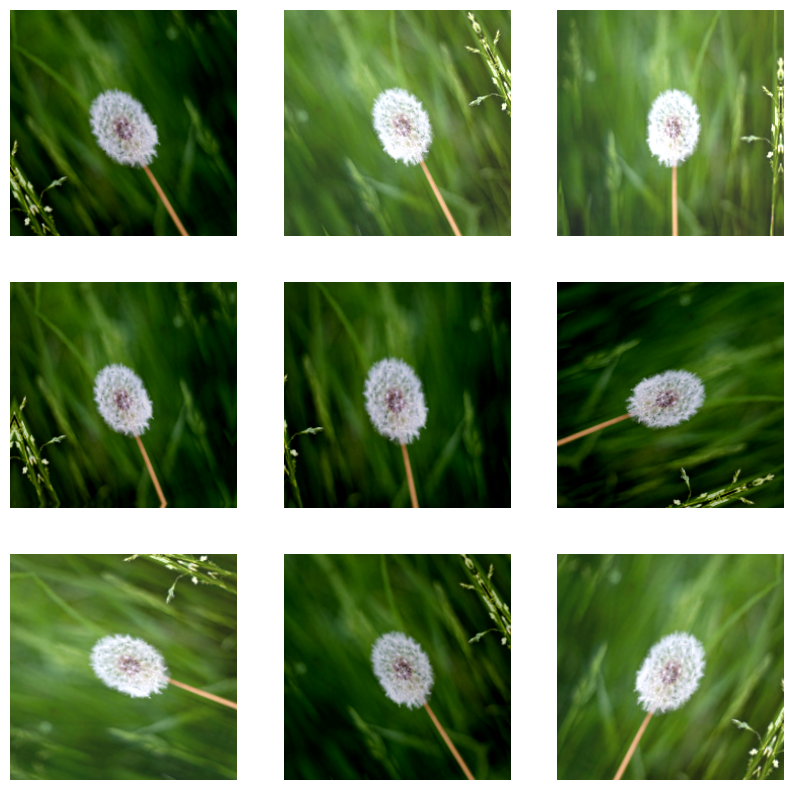

In [5]:
image_path = "/content/drive/MyDrive/7249354462_21925f7d95_n.jpg"

# Loading and preparing the image
img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0) # Adding the batch dimension

# Creating the 3x3 visual grid
plt.figure(figsize=(10, 10))
for i in range(9):
    augmented_image = data_augmentation(img_array)

    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(augmented_image[0].numpy().astype("uint8"))
    plt.axis("off")

plt.show()

Test with pre-trained model MobileNetV2

In [6]:
from tensorflow.keras.applications import MobileNetV2

#Pre-trained Base Model (MobileNetV2)
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False, # We drop the original 1000-class output
    weights='imagenet'
)

# Freeze the base model to preserve its learned features
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model A: WITHOUT Data Augmentation (The Baseline)

In [7]:
model_without_aug = models.Sequential([
    # Explicit Input Layer (Fixes the UserWarning)
    layers.Input(shape=(224, 224, 3)),

    # Preprocessing specific to MobileNetV2
    layers.Rescaling(1./127.5, offset=-1),

    # The frozen base model
    base_model,

    # Convert 3D feature maps to 1D feature vectors
    layers.GlobalAveragePooling2D(),

    # Custom classifier for your 5 flower classes
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(5, activation='softmax', name="output_flowers")
], name="Transfer_Learning_NO_Augmentation")

model_without_aug.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model_without_aug.summary()

Model: "Transfer_Learning_NO_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_flowers (Dense)          │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Model B: WITH Data Augmentation

In [8]:
model_with_aug = models.Sequential([
    data_augmentation,

    # Preprocessing specific to MobileNetV2
    layers.Rescaling(1./127.5, offset=-1),

    # The frozen base model
    base_model,

    # Convert 3D feature maps to 1D feature vectors
    layers.GlobalAveragePooling2D(),

    # Custom classifier for your 5 flower classes
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(5, activation='softmax', name="output_flowers")
], name="Transfer_Learning_WITH_Augmentation")

# Compile the model
model_with_aug.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_with_aug.summary()


Model: "Transfer_Learning_WITH_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation_pipeline      │ (1, 224, 224, 3)       │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (1, 7, 7, 1280)        │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (1, 1280)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 128)               │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_flowers (Dense)          │ (1, 5)                 │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Training Execution (OPZIONALE)

In [11]:
import tensorflow as tf
import pathlib

# Base parameters
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)

data_dir = pathlib.Path("/content/drive/MyDrive/flower_photos")
print(f"Loading images from: {data_dir}")

# Create the Training dataset (takes 80% of the images)
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2, # Reserves 20% for validation
  subset="training",
  seed=123, # Important to avoid overlapping training and validation
  image_size=IMAGE_SIZE,
  batch_size=BATCH_SIZE)

# Create the Validation dataset (takes the remaining 20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=IMAGE_SIZE,
  batch_size=BATCH_SIZE)

# Show the class names read from the folders
class_names = train_ds.class_names
print(f"Classes found: {class_names}")

# Performance optimization (loads data into memory while the GPU is working)
dummy_train = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
dummy_val = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

Loading images from: /content/drive/MyDrive/flower_photos
Found 3665 files belonging to 5 classes.
Using 2932 files for training.
Found 3665 files belonging to 5 classes.
Using 733 files for validation.
Classes found: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [13]:
import tensorflow as tf

# 1. Define the Early Stopping callback
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',    # We care about the validation accuracy
    patience=5,                # Stop if no improvement for 5 consecutive epochs
    restore_best_weights=True  # Automatically roll back to the best performing model
)

EPOCHS = 20

print("======================================================")
print(" STARTING EXPERIMENT A: Model WITHOUT Augmentation ")
print("======================================================")
history_no_aug = model_without_aug.fit(
    dummy_train,
    validation_data=dummy_val,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

print("\n======================================================")
print(" STARTING EXPERIMENT B: Model WITH Augmentation ")
print("======================================================")
history_with_aug = model_with_aug.fit(
    dummy_train,
    validation_data=dummy_val,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

 STARTING EXPERIMENT A: Model WITHOUT Augmentation 
Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 1190s 13s/step - accuracy: 0.8527 - loss: 0.4322 - val_accuracy: 0.8990 - val_loss: 0.3098
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9168 - loss: 0.2504 - val_accuracy: 0.8936 - val_loss: 0.3144
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9478 - loss: 0.1630 - val_accuracy: 0.9127 - val_loss: 0.2604
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9618 - loss: 0.1174 - val_accuracy: 0.9113 - val_loss: 0.2623
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.9751 - loss: 0.0838 - val_accuracy: 0.9168 - val_loss: 0.2688
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9826 - loss: 0.0671 - val_accuracy: 0.9004 - val_loss: 0.2751
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.9870 - loss: 0.0521 - val_accuracy: 0.8990 - val_loss: 0.2869
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accu

Compare the 2 models

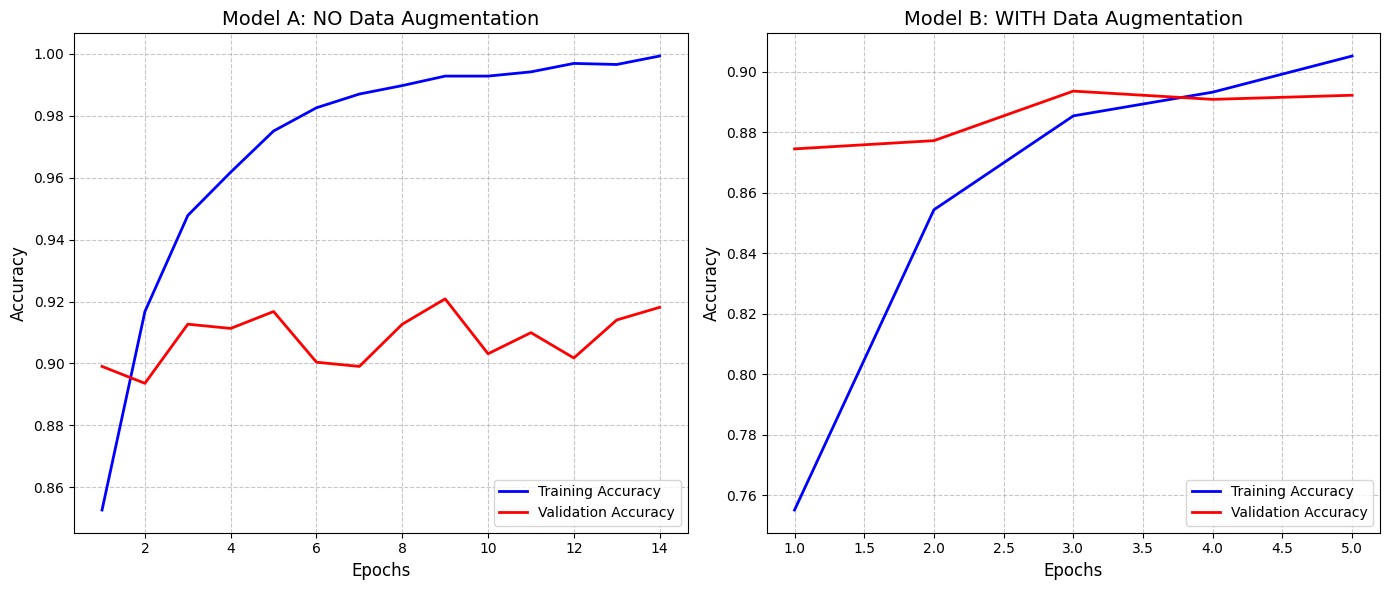

In [15]:
import matplotlib.pyplot as plt

# 1. Extract accuracy data from both models
acc_no_aug = history_no_aug.history['accuracy']
val_acc_no_aug = history_no_aug.history['val_accuracy']

acc_with_aug = history_with_aug.history['accuracy']
val_acc_with_aug = history_with_aug.history['val_accuracy']

# Note: We use len() because Early Stopping might have stopped training before 20 epochs
epochs_range_no_aug = range(1, len(acc_no_aug) + 1)
epochs_range_with_aug = range(1, len(acc_with_aug) + 1)

# 2. Create a wide figure to hold two plots side-by-side
plt.figure(figsize=(14, 6))

# --- Plot 1: Model A (Without Augmentation) ---
plt.subplot(1, 2, 1)
plt.plot(epochs_range_no_aug, acc_no_aug, 'b-', label='Training Accuracy', linewidth=2)
plt.plot(epochs_range_no_aug, val_acc_no_aug, 'r-', label='Validation Accuracy', linewidth=2)
plt.title('Model A: NO Data Augmentation', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)

# --- Plot 2: Model B (With Augmentation) ---
plt.subplot(1, 2, 2)
plt.plot(epochs_range_with_aug, acc_with_aug, 'b-', label='Training Accuracy', linewidth=2)
plt.plot(epochs_range_with_aug, val_acc_with_aug, 'r-', label='Validation Accuracy', linewidth=2)
plt.title('Model B: WITH Data Augmentation', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)

# 3. Adjust layout and display the result
plt.tight_layout()
plt.show()